# 03 – Modeling and evaluation

**Stages 5–7 of the project.** The production version of this code is `src/train.py`;
this notebook walks through the same ideas step by step.

**The plan**
1. Split: 80% training, 20% test, **stratified** (same failure share in both)
2. Baselines first: "always no failure" and expert rules
3. Models from simple to powerful, compared with **5-fold cross-validation** on training data only
4. Choose the alarm threshold by **business cost** (missed failure = 10, false alarm = 1)
5. Evaluate **once** on the test set

In [1]:
import sys
sys.path.append("..")          # lets Python find the src folder
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_prepared, split_train_test, FEATURES_RAW, FEATURES_PHYSICS
from src.modeling import (candidate_models, out_of_fold_probabilities, best_threshold,
                          scores_at, ranking_scores, cost_curve)
from src.rules import FailureRules

%matplotlib inline
from src.plotting import set_style
set_style()

df = load_prepared()
train, test = split_train_test(df)
y_train, y_test = train["failure"].to_numpy(), test["failure"].to_numpy()
print(f"Train: {len(train)} runs, {y_train.mean():.2%} failures")
print(f"Test:  {len(test)} runs, {y_test.mean():.2%} failures   <- stratified: same share")

Train: 8000 runs, 3.39% failures
Test:  2000 runs, 3.40% failures   <- stratified: same share


## 1. Preprocessing – what goes in, what stays out

- **In:** product quality (L=0, M=1, H=2), 5 sensors, 3 physics features
- **Out:** `UDI`, `Product ID` (identifiers), `TWF`…`RNF` (**data leakage**: they describe the failure itself)
- **No missing values, no duplicates** → no imputation needed (see notebook 01)
- **Scaling** only for logistic regression (inside a pipeline, so it is learned on training folds only). Tree models don't need it.
- **Imbalance:** `class_weight="balanced"` makes each failure count as much as ~29 normal runs.

In [2]:
print('Raw features:     ', FEATURES_RAW)
print('Physics features: ', FEATURES_PHYSICS)

Raw features:      ['product_quality', 'air_temp_k', 'process_temp_k', 'speed_rpm', 'torque_nm', 'tool_wear_min']
Physics features:  ['product_quality', 'air_temp_k', 'process_temp_k', 'speed_rpm', 'torque_nm', 'tool_wear_min', 'temp_diff_k', 'power_w', 'strain_nm_min']


## 2. Why cross-validation?

If we tuned and compared models on the test set, we would slowly *fit to the test set* and fool ourselves.
Instead, the training data is split into 5 folds: train on 4, predict the 5th, repeat. Every training run gets
an **out-of-fold** prediction from a model that never saw it.

In [3]:
rf = candidate_models()["Random forest"]
proba_raw = out_of_fold_probabilities(rf, train[FEATURES_RAW], y_train)
proba_phys = out_of_fold_probabilities(rf, train[FEATURES_PHYSICS], y_train)
print("Random forest, raw sensors:      PR-AUC = %.3f" % ranking_scores(y_train, proba_raw)["pr_auc"])
print("Random forest, sensors + physics: PR-AUC = %.3f" % ranking_scores(y_train, proba_phys)["pr_auc"])

Random forest, raw sensors:      PR-AUC = 0.756
Random forest, sensors + physics: PR-AUC = 0.894


**PR-AUC** (area under the precision-recall curve) measures how well a model ranks failures above normal runs,
across all thresholds. Random guessing scores about 0.034 here (the failure share). The physics features give a
big jump – feature engineering from domain knowledge beats a fancier algorithm.

## 3. Choosing the alarm threshold by business cost

In [4]:
thresholds, costs = cost_curve(y_train, proba_phys)
threshold, cost = best_threshold(y_train, proba_phys)
plt.figure(figsize=(9, 4))
plt.plot(thresholds, costs)
plt.axvline(threshold, linestyle="--", color="#eb6834")
plt.xlabel("Alarm threshold")
plt.ylabel("Total business cost")
plt.title(f"Lowest cost {cost} at threshold {threshold:.2f}")
plt.show()
scores_at(y_train, (proba_phys >= threshold).astype(int))

{'recall': 0.8450184501845018,
 'precision': 0.9015748031496063,
 'caught_failures': 229,
 'missed_failures': 42,
 'false_alarms': 25,
 'business_cost': 445}

A threshold of 0.5 is just a habit. With a missed failure costing 10× a false alarm, the cheapest
threshold is lower: we accept a few more false alarms to catch more failures.

**Note:** because of `class_weight`, the model's output is a **risk score**, not a calibrated real-world
probability. It ranks runs correctly, but "0.6" does not mean "60% chance". That's why the dashboard calls it a risk score.

## 4. The full comparison (from `src/train.py`)

In [5]:
pd.read_csv('../reports/model_comparison_cv.csv')[['model', 'features', 'pr_auc', 'recall', 'precision', 'missed_failures', 'false_alarms', 'business_cost']].sort_values('business_cost')

,model,features,pr_auc,recall,precision,missed_failures,false_alarms,business_cost
9,"Expert rules (heat, power, overstrain)",Physics thresholds,NaN,0.8376,1.0000,44,0,440
7,Random forest,Sensors + physics,0.8937,0.8450,0.9016,42,25,445
8,Gradient boosting,Sensors + physics,0.8849,0.8339,0.8968,45,26,476
10,Expert rules + tool-wear limit,Physics thresholds,NaN,0.9594,0.3852,11,415,525
6,Decision tree,Sensors + physics,0.8060,0.7897,0.7509,57,71,641
4,Gradient boosting,Raw sensors,0.7886,0.8229,0.5747,48,165,645
3,Random forest,Raw sensors,0.7559,0.8081,0.6050,52,143,663
2,Decision tree,Raw sensors,0.5471,0.7196,0.4577,76,231,991
5,Logistic regression,Sensors + physics,0.4531,0.6162,0.3465,104,315,1355
1,Logistic regression,Raw sensors,0.4345,0.5720,0.3326,116,311,1471


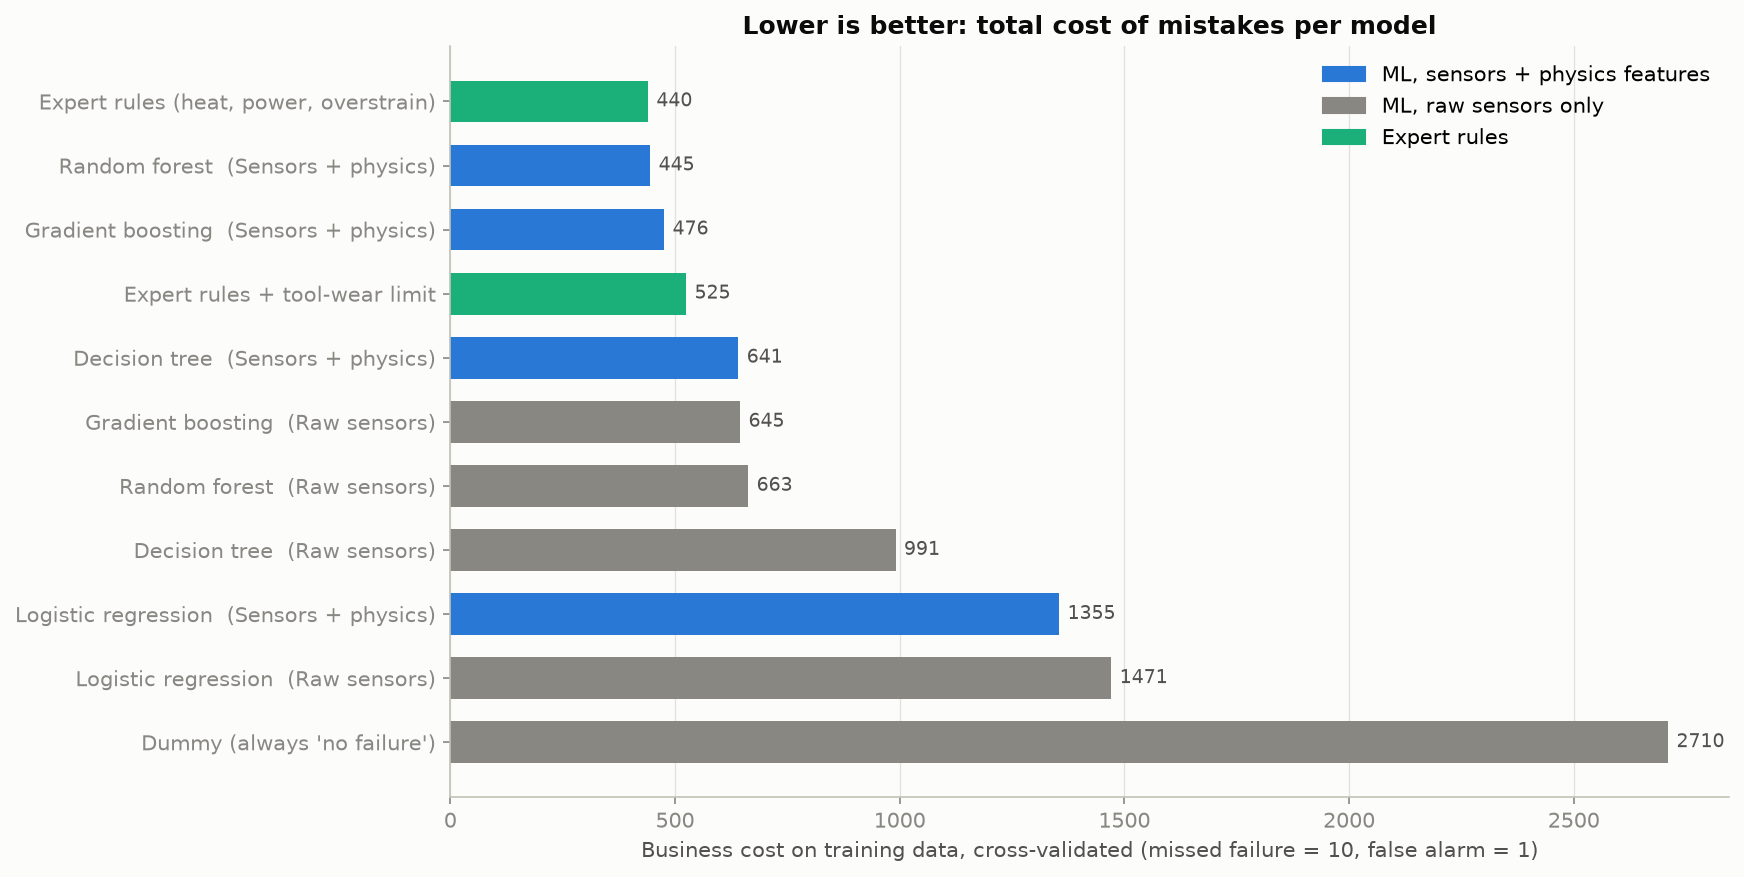

In [6]:
from IPython.display import Image
Image('../reports/figures/model_comparison.png')

**Honest reading of this table**
- Physics features improve every model.
- Random forest is the best ML model.
- The **expert rules are just as good** (cost 440 vs. 445). That's because this synthetic dataset was generated
  from exactly such physical limits, which our EDA rediscovered. On a real machine the limits are unknown, noisy
  and drifting – the ML model learns them from data, while rules need an expert to find and maintain them.

## 5. Final evaluation – the test set, used once

In [7]:
pd.read_csv('../reports/test_results.csv')[['model', 'recall', 'precision', 'caught_failures', 'missed_failures', 'false_alarms', 'business_cost']]

,model,recall,precision,caught_failures,missed_failures,false_alarms,business_cost
0,Random forest (Sensors + physics),0.8235,0.9333,56,12,4,124
1,"Expert rules (heat, power, overstrain)",0.8235,1.0000,56,12,0,120
2,Expert rules + tool-wear limit,0.9559,0.3299,65,3,132,162
3,Dummy (always 'no failure'),0.0000,0.0000,0,68,0,680


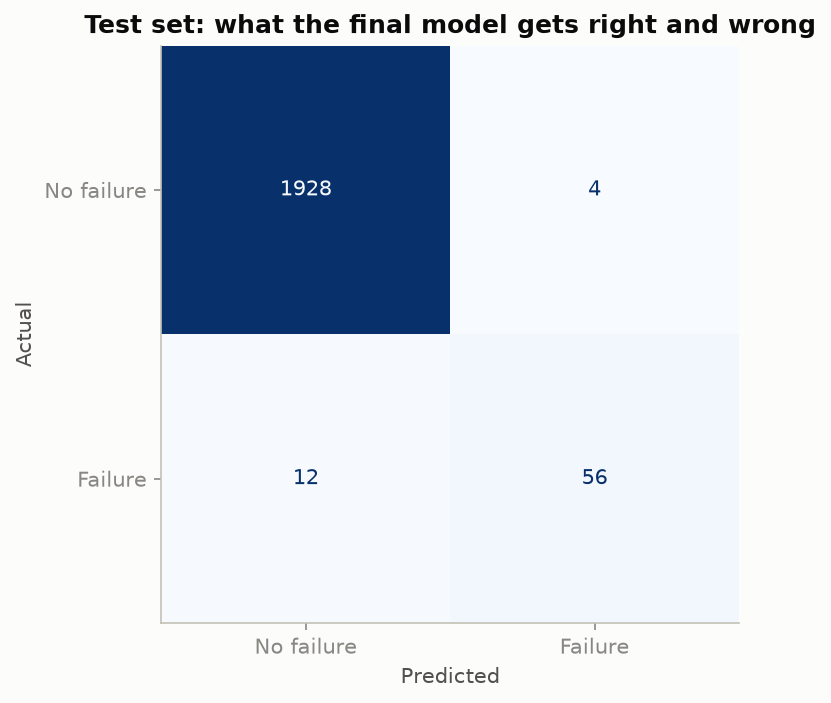

In [8]:
Image('../reports/figures/confusion_matrix_test.png')

In [9]:
import json
m = json.load(open("../reports/metrics.json"))
print("Missed failures on the test set, by type:", m["test_missed_failures_by_type"])

Missed failures on the test set, by type: {'TWF': 9, 'HDF': 1, 'PWF': 0, 'OSF': 0, 'RNF': 0, 'no type given': 2}


**The key insight:** the model catches every power and overstrain failure and all but one heat failure.
Almost all misses are **tool-wear failures**, which happen at a *random* moment after ~200 minutes.
A snapshot of sensor values cannot predict a random event.

**Engineering recommendation:** combine the model with a **planned tool change at ~200 minutes of wear**.
The model handles the physical failure modes; the maintenance plan handles tool wear. Knowing what your
model *can't* do, and proposing an alternative, is what turns a model into a solution.

## 6. Which failure type? (multi-label model)

In [10]:
pd.DataFrame(m['type_model']['per_type']).T

,test_cases,recall,precision
TWF,10.0,0.7,1.000000
HDF,29.0,1.0,1.000000
PWF,13.0,1.0,1.000000
OSF,16.0,1.0,0.888889


In [11]:
print('Top predicted type correct for %.0f%% of test failures' % (100 * m['type_model']['top_type_correct']))

Top predicted type correct for 97% of test failures
